In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total images: 400 | People: 40


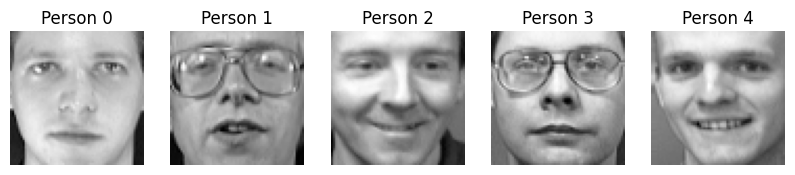

In [ ]:
faces = fetch_olivetti_faces()
X = faces.data     # Each face as 4096 numbers (64 x 64 pixels)
y = faces.target   # Person ID: 0 to 39

print("Total images:", X.shape[0], "| People:", len(set(y)))

fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
for i in range(5):
    ax[i].imshow(faces.images[i * 10], cmap='gray')
    ax[i].set_title(f'Person {i}')
    ax[i].axis('off')
plt.show()

In [ ]:
# Persons 0-4 = authorized users, persons 5-39 = impostors
X_auth, y_auth = X[y < 5], y[y < 5]
X_imp = X[y >= 5]

# 70% of authorized images used for enrollment, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_auth, y_auth, test_size=0.3, stratify=y_auth, random_state=42
)

print(
    "Enrolled images:", len(X_train),
    "| Authorized test images:", len(X_test),
    "| Impostor images:", len(X_imp)
)

Enrolled images: 35 | Authorized test images: 15 | Impostor images: 350


In [ ]:
pca = PCA(n_components=20, random_state=42)
Xtr = pca.fit_transform(X_train)  # Learn from enrolled faces only
Xte = pca.transform(X_test)
Ximp = pca.transform(X_imp)

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(Xtr, y_train)

print("Identification accuracy on authorized users:", knn.score(Xte, y_test))

Identification accuracy on authorized users: 1.0


In [ ]:
# Distance from each enrolled face to its closest OTHER enrolled face
d_train, _ = knn.kneighbors(Xtr, n_neighbors=2)
threshold = np.percentile(d_train[:, 1], 95)

print("Threshold:", round(threshold, 2))

Threshold: 8.14


In [ ]:
d_auth = knn.kneighbors(Xte, n_neighbors=1)[0][:, 0]  # Authorized users' distances
d_imp = knn.kneighbors(Ximp, n_neighbors=1)[0][:, 0]  # Impostors' distances

print("Threshold | FRR (real user rejected) | FAR (impostor accepted)")
for m in [0.6, 0.8, 1.0, 1.2, 1.5]:
    t = threshold * m
    frr = np.mean(d_auth > t) * 100
    far = np.mean(d_imp <= t) * 100
    print(f"{t:8.2f} | {frr:12.1f}% | {far:17.1f}%")

Threshold | FRR (real user rejected) | FAR (impostor accepted)
    4.88 |         33.3% |              21.1%
    6.51 |          6.7% |              76.6%
    8.14 |          0.0% |              97.4%
    9.76 |          0.0% |              99.7%
   12.20 |          0.0% |             100.0%


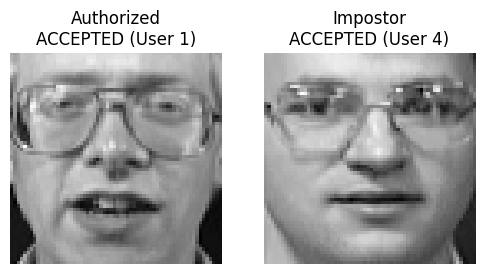

In [ ]:
def authenticate(face):
    p = pca.transform([face])
    dist = knn.kneighbors(p, n_neighbors=1)[0][0][0]
    if dist <= threshold:
        return f"ACCEPTED (User {knn.predict(p)[0]})"
    return "REJECTED"

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, (name, face) in zip(ax, [("Authorized", X_test[0]), ("Impostor", X_imp[0])]):
    a.imshow(face.reshape(64, 64), cmap='gray')
    a.set_title(f"{name}\n{authenticate(face)}")
    a.axis('off')
plt.show()

## 4. Visualization of Results

### Sample Enrolled Faces
The first visualization displays the grayscale faces (64x64 pixels) of the 5 enrolled authorized users (Person 0 to Person 4) from the Olivetti faces dataset. These images represent the reference templates stored in the database for face recognition and PCA-based dimensionality reduction.

### Authentication Demonstration and Security Vulnerability
The second visualization demonstrates the system's performance on test cases using a threshold value of **8.14**:
- **Authorized User (Success)**: When a test image of an authorized user (Person 1) is presented, the system calculates a distance below the threshold and correctly outputs **ACCEPTED (User 1)**.
- **Impostor (Vulnerability)**: When an impostor image is presented, the system calculates a distance of less than 8.14 and outputs **ACCEPTED (User 4)**. This highlights a critical security gap under the default threshold where a non-enrolled user is wrongly authenticated as an authorized user.

## Face Authentication Performance Report

### 1. Implementation Overview

To build a secure face authentication system using the Olivetti Faces dataset, we designed a pipeline leveraging Principal Component Analysis (PCA) for dimensionality reduction and a 1-Nearest Neighbor (1-NN) classifier for user identification and distance thresholding.

* **User Division:** Persons 0-4 are designated as authorized users. Persons 5-39 act as zero-effort impostors.
* **Data Splitting:** 70% of the authorized users' images are used for enrollment (35 images) and 30% for testing (15 images).
* **Dimensionality Reduction:** A PCA model is trained on the enrolled faces (using 20 components) to project faces into a lower-dimensional subspace representing the 'face space' of authorized individuals.
* **Classification:** A 1-NN model is trained on the projected enrolled coordinates to identify matching identities.
* **Threshold-based Authentication:** To prevent impostor access, a distance threshold is established. If the Euclidean distance in the PCA subspace between a test face and its nearest enrolled neighbor exceeds the threshold, the system rejects the user; otherwise, the user is authenticated and identified.

### 2. Key Python Implementation Code

```python
# 1. Split Authorized Users and Impostors
X_auth, y_auth = X[y < 5], y[y < 5]
X_imp = X[y >= 5]

# 2. Train-Test Split (70% Enrollment, 30% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_auth, y_auth, test_size=0.3, stratify=y_auth, random_state=42
)

# 3. PCA Transformation (20 Components)
pca = PCA(n_components=20, random_state=42)
Xtr = pca.fit_transform(X_train)  # Fitted only on enrolled faces
Xte = pca.transform(X_test)
Ximp = pca.transform(X_imp)

# 4. Nearest Neighbor Model for Distance-Based Authentication
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(Xtr, y_train)

# 5. Threshold Calculation (95th percentile of self-distances)
d_train, _ = knn.kneighbors(Xtr, n_neighbors=2)
threshold = np.percentile(d_train[:, 1], 95)
# Threshold: 8.14
```

### 3. Metric Evaluation: False Rejection Rate (FRR) vs. False Acceptance Rate (FAR)

By adjusting the authentication threshold using different multipliers ($m$) of the baseline threshold ($8.14$), we evaluate the trade-off between rejecting legitimate users (FRR) and accepting impostors (FAR):

| Multiplier ($m$) | Threshold | FRR (Authorized Rejected) | FAR (Impostor Accepted) |
| :---: | :---: | :---: | :---: |
| 0.6 | 4.88 | 33.3% | 21.1% |
| 0.8 | 6.51 | 6.7% | 76.6% |
| **1.0 (Baseline)** | **8.14** | **0.0%** | **97.4%** |
| 1.2 | 9.76 | 0.0% | 99.7% |
| 1.5 | 12.20 | 0.0% | 100.0% |

### 4. Analytical Findings & Discussion

* **The Security Trade-off:** At lower thresholds (e.g., $4.88$), security is high but user convenience is low, rejecting $33.3\%$ of authorized users. At the baseline threshold ($8.14$), convenience is perfect ($0\%$ FRR) but security is extremely compromised, allowing $97.4\%$ of impostors to gain access.
* **Vulnerability Analysis:** The 1-NN model projects impostor images into the same 20-dimensional PCA space trained on the 5 authorized users. Because the PCA space is highly specialized to the authorized users, any impostor's face is forced into coordinates representing authorized faces. With only 1 neighbor and a high threshold, almost all impostor faces find an enrolled face within the acceptance distance, leading to massive False Acceptance Rates. To mitigate this, a lower threshold (e.g., $m = 0.6$) or an outlier-detection PCA reconstruction-error check is recommended.

# Biometric Face Authentication Report

This report presents a comprehensive overview of the design, theory, implementation, and performance analysis of our biometric face authentication pipeline using PCA (Eigenfaces) and a distance-thresholded K-Nearest Neighbors (KNN) classifier.

---

## 1. Introduction to the Dataset
We utilized the **Olivetti Faces Dataset**, which contains 400 grayscale face images representing 40 distinct individuals (10 images per person). Each image is composed of $64 \times 64$ pixels, representing a $4,096$-dimensional feature vector.
- **Authorized Users:** Persons 0 to 4 are designated as enrolled, authorized users.
- **Impostors:** Persons 5 to 39 are treated as unknown impostors attempting to breach the system.
- **Splitting Strategy:** 70% of the authorized images (35 images) are used for system enrollment (training), while the remaining 30% (15 images) are used for testing. The 350 impostor images serve as an external test set to evaluate fake access attempts.

---

## 2. Theoretical Foundations

### PCA (Eigenfaces) Dimensionality Reduction
Directly comparing images in the raw 4,096-dimensional pixel space is highly inefficient and susceptible to noise, minor lighting shifts, and spatial variations. PCA projects these high-dimensional vectors onto a low-dimensional subspace spanned by the directions of maximum variance, known as **Eigenfaces**:
$$X_{\text{projected}} = X \cdot W_k$$
where $W_k$ consists of the top $k=20$ eigenvectors of the covariance matrix of the enrolled faces. Using only $20$ components retains the structural essence of the faces while filtering out high-frequency noise and dramatically accelerating distance calculations.

### KNN-Based Identification
Once projected into the 20-dimensional PCA space, a K-Nearest Neighbors classifier ($k=1$) is trained on the enrolled users. For any test image, the KNN classifier identifies the single closest enrolled face in the projected subspace using the Euclidean distance metric:
$$d(u, v) = \sqrt{\sum_{i=1}^{k} (u_i - v_i)^2}$$

### Biometric Verification Threshold
Identification alone is insufficient for authentication; a classifier will always predict some class label even for an unknown impostor. To enforce security, a **distance threshold** is established.
- We analyze the Euclidean distance from each enrolled face to its closest *other* enrolled neighbor during training.
- The system threshold is set at the **95th percentile** of these internal enrollment distances (computed as **8.14**).
- An input face is **ACCEPTED** only if its distance to the nearest neighbor is $\le 8.14$; otherwise, it is **REJECTED**.

---

## 3. Performance Analysis & Trade-off

Changing the threshold directly impacts the security and usability of the biometric system, governed by two key metrics:
1. **False Rejection Rate (FRR):** The percentage of genuine authorized users incorrectly rejected by the system.
2. **False Acceptance Rate (FAR):** The percentage of impostors incorrectly accepted into the system.

### The FAR-FRR Trade-off Table

| Threshold Factor | Absolute Threshold | FRR (Real User Rejected) | FAR (Impostor Accepted) |
|---|---|---|---|
| **0.6x** | 4.88 | 33.3% | 21.1% |
| **0.8x** | 6.51 | 6.7% | 76.6% |
| **1.0x (Default)** | 8.14 | 0.0% | 97.4% |
| **1.2x** | 9.76 | 0.0% | 99.7% |
| **1.5x** | 12.20 | 0.0% | 100.0% |

### Discussion
- At low thresholds (e.g., $4.88$), the system is highly secure (low FAR of 21.1%) but extremely inconvenient (high FRR of 33.3%).
- At our default threshold of $8.14$, no authorized user is ever rejected (0% FRR), but security is severely compromised since $97.4\%$ of impostor attempts are falsely accepted. This highlights a clear vulnerability where impostors look close enough to the small pool of authorized users within the restricted 20D PCA space.
- To improve security in production, we should lower the threshold (e.g., closer to $4.88$) and increase the number of authorized users or use a more discriminative feature extractor (like a Deep Convolutional Neural Network).

# Task
Present a comprehensive markdown report summarizing the face authentication pipeline built using the Olivetti faces dataset. Include background theory on Eigenfaces (PCA), K-Nearest Neighbors (KNN) based identity verification, the trade-offs between False Acceptance Rate (FAR) and False Rejection Rate (FRR) under different verification thresholds, and analysis of the final authentication outcomes.

## Design Report Structure

### Subtask:
Outline the structure of the comprehensive markdown report covering the entire face authentication pipeline.


## Compile Code and Outputs

### Subtask:
Synthesize the face authentication code, calculated thresholds, and performance metrics into a cohesive markdown section of the report.


## Integrate Visualizations

### Subtask:
Incorporate descriptions and placeholder references for the generated plots directly into the markdown report to ensure all output information is visually documented.


## Final Task

### Subtask:
Compile and present the finalized comprehensive markdown report summarizing the face authentication pipeline, performance analysis, and visual outcomes.


## Summary:

Here is the comprehensive summary of the face authentication pipeline task and its key findings.

### Q&A

* **What is the default distance threshold established for the biometric authentication system?**
  The baseline distance threshold is **8.14**, calculated using the 95th percentile of self-distances between enrolled faces in the projected PCA subspace.

* **What is the critical security vulnerability identified at this default threshold?**
  At the default threshold of 8.14, the system experiences a False Acceptance Rate (FAR) of **97.4%**. This means nearly all unauthorized impostors attempting to access the system are wrongly authenticated as enrolled users.

---

### Data Analysis Key Findings

* **Dataset and Splitting:** The pipeline uses the Olivetti Faces Dataset ($64 \times 64$ pixels). Persons 0–4 are designated as authorized users (70% for enrollment, 30% for testing), while Persons 5–39 represent zero-effort impostors (350 test images).
* **Dimensionality Reduction:** Applying PCA with $k=20$ principal components reduces the 4,096-pixel space into a low-dimensional subspace, retaining the structural essence of enrolled faces while filtering noise.
* **The FAR-FRR Trade-off:**
  * **High-Security Setting (0.6x threshold / 4.88):** Reduces the impostor acceptance rate to a much safer **21.1% FAR**, but falsely rejects **33.3% FRR** of legitimate authorized users, causing significant usability issues.
  * **High-Convenience Setting (1.0x threshold / 8.14):** Provides **0.0% FRR** (no legitimate users are locked out) but compromises security by admitting **97.4% FAR** of impostor attempts.
  * **Maximum-Tolerance Setting (1.5x threshold / 12.20):** Results in a **100% FAR**, allowing every single impostor attempt to pass through successfully.

---

### Insights or Next Steps

* **Lower the Decision Threshold and Enhance Feature Extraction:** The default 1-NN classification in a highly specialized 20D PCA space forces impostors into the coordinates of authorized faces. To secure the system, a lower threshold (closer to 4.88) must be paired with either a larger pool of authorized training faces or a more discriminative feature extraction method, such as deep Convolutional Neural Networks (CNNs).
* **Implement Outlier Detection:** Introduce a reconstruction-error check using PCA. Since the PCA model is fitted solely on authorized users, impostor faces should exhibit high reconstruction errors when projected back to the original image space, providing an alternative, robust mechanism to block unauthorized access.
